
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona MX- Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



# Introducción

* Los modelos lineales son fácilmente interpretables, sin embargo, en general, su calidad predictiva es muy limitada, por lo cual es necesario **explorar transformaciones y combinaciones de los predictores originales**.

* A este proceso se le denomina **modelado** y se considera más un arte que una ciencia.

* En el proceso de modelado, la evaluación de los modelos construidos debe realizarse con un conjunto de datos diferente al empleado para su construcción, a este proceso se le denomina **validación** y se explora en este documento.     
Validación.
Con la validación buscamos dos objetivos:

Evaluar la calidad de diferentes modelos para identificar el mejor.
Estimar el error que cometeremos con el mejor modelo identificado cuando lo apliquemos a nuevas observaciones, observaciones que no han sido utilizadas para construir el modelo. A este error lo denominamos error de generalización.
La idea de esta técnica es la de dividir el conjunto de datos original, en tres subconjuntos:

Conjunto de entrenamiento: utilizado para construir el modelo (puede abarcar entre el 50% y el 70% de las observaciones del conjunto original).
Conjunto de validación: se utiliza para evaluar la calidad predictiva de diferentes modelos. Se forma por la mitad de las observaciones del conjunto original que no forman parte del conjunto de entrenamiento.
Conjunto de prueba: con este conjunto se estima el error de generalización, esto es, el error que se espera obtener del modelo cuando se aplique a nuevos casos.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

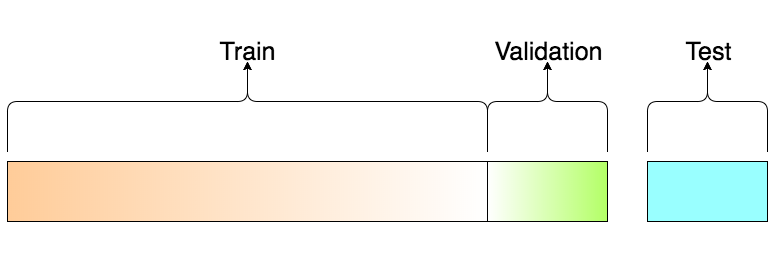

**Fuente de la imagen**: http://mateos.io/blog/train-test-split/

En las siguientes celdas se explora un ejemplo de la aplicación de la validación cruzada para evaluar diferentes modelos.

# Ejemplo

In [ ]:
sales = pd.read_csv("advertising.csv")
sales.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## Separación (entrenamiento, validación, prueba)

Separamos el conjunto de datos en tres subconjuntos: entrenamiento (60% de las observaciones), validación (20%) y prueba (20%).

In [ ]:
from sklearn.model_selection import train_test_split

train, val = train_test_split(sales, test_size=0.4, random_state=0) # 60% entrenamiento, 40% validación y prueba

In [ ]:
train.shape # conjunto empleado para ajustar modelos (para aprender)

(120, 4)

In [ ]:
val.shape # conjunto empleado para evaluar los modelos que se construirán

(80, 4)

Separamos ahora el conjunto de prueba del de validación.

In [ ]:
val, test = train_test_split(val, test_size=0.5, random_state=0)

Los conjuntos tienen ahora las siguientes dimensiones.

In [ ]:
train.shape # 60% de las observaciones

(120, 4)

In [ ]:
val.shape # 20% de las observaciones

(40, 4)

In [ ]:
test.shape # 20% de las observaciones

(40, 4)

## Predictores, respuesta

In [ ]:
preds = ['TV', 'radio', 'newspaper']

X_train = train[preds]
X_val = val[preds]
X_test = test[preds]

y_train = train['sales']
y_val = val['sales']
y_test = test['sales']

## Modelo 1

Modelo lineal con todos los predictores:

$$\widehat{\text{sales}} = \widehat{a}_0+\widehat{a}_1\text{TV}+\widehat{a}_2\text{radio}+\widehat{a}_3\text{newspaper}$$

Observa que construiremos el modelo empleando solamente los datos de **entrenamiento**.


In [ ]:
X_train.head()

,TV,radio,newspaper
187,191.1,28.7,18.2
46,89.7,9.9,35.7
138,43.0,25.9,20.5
195,38.2,3.7,13.8
108,13.1,0.4,25.6


In [ ]:
from sklearn.linear_model import LinearRegression

lr1 = LinearRegression().fit(X_train, y_train)

Evaluamos la calidad del modelo empleando el conjunto de **validación**.

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error


yp1 = lr1.predict(X_val)
r2_score(y_val, yp1)

0.9236337073883868

In [ ]:
mean_squared_error(y_val, yp1)

1.7454236883270713

Parámetros del modelo

In [ ]:
pars1 = [lr1.intercept_]+list(lr1.coef_)
pars1 = pd.DataFrame({'coeficientes_estimados': pars1}, index=['Intersección']+list(X_val.columns))
pars1

,coeficientes_estimados
Intersección,2.811937
TV,0.044405
radio,0.196801
newspaper,0.003678


## Modelo 2

Eliminamos la variable `newspaper`:

$$\widehat{\text{sales}} = \widehat{a}_0+\widehat{a}_1\text{TV}+\widehat{a}_2\text{radio}$$


In [ ]:
X2_train = X_train.drop('newspaper', axis=1)
X2_val = X_val.drop('newspaper', axis=1)

X2_train.head()

,TV,radio
187,191.1,28.7
46,89.7,9.9
138,43.0,25.9
195,38.2,3.7
108,13.1,0.4


In [ ]:
lr2 = LinearRegression().fit(X2_train, y_train)

In [ ]:
yp2 = lr2.predict(X2_val)

r2_score(y_val, yp2)

0.9257417482628768

In [ ]:
mean_squared_error(y_val, yp2)

1.6972424246770275

In [ ]:
pars2 = [lr2.intercept_]+list(lr2.coef_)
pars2 = pd.DataFrame({'coeficientes_estimados': pars2}, index=['Intersección']+list(X2_val.columns))
pars2

,coeficientes_estimados
Intersección,2.880115
TV,0.044461
radio,0.198102


## Modelo 3

Consideramos un término de interacción entre los predictores:

$$\widehat{\text{sales}} = \widehat{a}_0+\widehat{a}_1\text{TV}+\widehat{a}_2\text{radio}+\widehat{a}_3\text{TV}\times\text{radio}$$

Este predictor resalta la importancia de invertir en ambos medios al mismo tiempo.

In [ ]:
X3_train = X2_train
X3_train['TV:radio'] = X3_train['TV']*X3_train['radio'] # (observar que si alguno de ellos es cero, este término se ignora)

X3_val = X2_val
X3_val['TV:radio'] = X3_val['TV']*X3_val['radio']

X3_train.head()

,TV,radio,TV:radio
187,191.1,28.7,5484.57
46,89.7,9.9,888.03
138,43.0,25.9,1113.70
195,38.2,3.7,141.34
108,13.1,0.4,5.24


In [ ]:
lr3 = LinearRegression().fit(X3_train, y_train)
yp3 = lr3.predict(X3_val)
r2_score(y_val, yp3)

0.9752562418346016

In [ ]:
mean_squared_error(y_val, yp3)

0.5655419447919491

In [ ]:
pars3 = [lr3.intercept_]+list(lr3.coef_)
pars3 = pd.DataFrame({'coeficientes_estimados': pars3}, index=['Intersección']+list(X3_val.columns))
pars3

,coeficientes_estimados
Intersección,6.664875
TV,0.019039
radio,0.034709
TV:radio,0.001078


## Modelo 4

Agregamos una transformación no lineal del predictor `TV`, basándonos en la siguiente gráfica de dispersión.


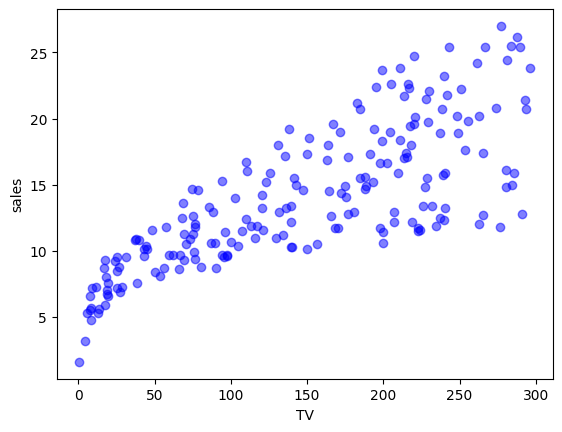

In [ ]:
plt.plot(sales['TV'], sales['sales'], 'bo', alpha=0.5)
plt.xlabel('TV')
plt.ylabel('sales')
plt.show()

Exploramos qué tan bien se ajusta una **transformación logarítmica** sobre la variable `TV`

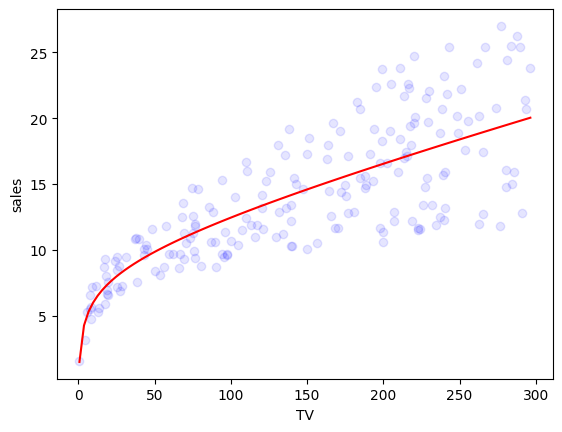

In [ ]:
X_log = pd.DataFrame({'TV': X_train['TV'], 'logTV': np.log(X_train['TV'])})
tv_reg = LinearRegression().fit(X_log, y_train)

plt.plot(sales['TV'], sales['sales'], 'bo', alpha=0.1)

tv = np.linspace(np.min(sales['TV']), np.max(sales['TV']), 100)
sales_p = tv_reg.intercept_ + tv_reg.coef_[0]*tv+tv_reg.coef_[1]*np.log(tv)

plt.plot(tv, sales_p, 'r')
plt.xlabel('TV')
plt.ylabel('sales')
plt.show()


La transformación logarítmica es una posibilidad, entre muchas. Exploremos una transformación con un radical (**raíz cuadrada**)



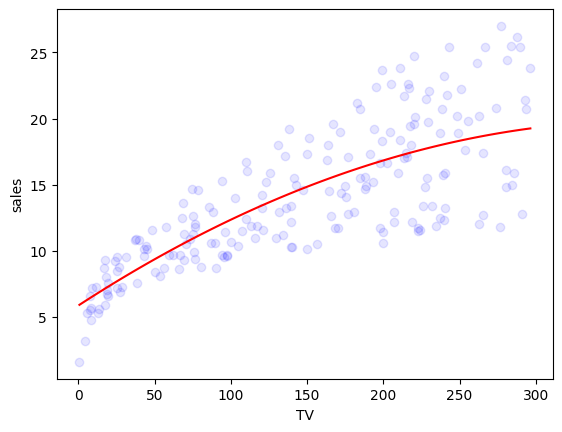

In [ ]:
X_sqrt = pd.DataFrame({'TV': X_train['TV'], 'sqrtTV': X_train['TV']**2})
tv_reg = LinearRegression().fit(X_sqrt, y_train)

plt.plot(sales['TV'], sales['sales'], 'bo', alpha=0.1)

tv = np.linspace(np.min(sales['TV']), np.max(sales['TV']), 100)
sales_p = tv_reg.intercept_ + tv_reg.coef_[0]*tv+tv_reg.coef_[1]*(tv)**2

plt.plot(tv, sales_p, 'r')
plt.xlabel('TV')
plt.ylabel('sales')
plt.show()


El modelo modelo propuesto es:

$$\widehat{\text{sales}} = \widehat{a}_0+\widehat{a}_1\text{TV}+\widehat{a}_2\text{radio}+\widehat{a}_3\text{TV}\times\text{radio}+\widehat{a}_4{\log(\text{TV})}$$



In [ ]:
X4_train = X3_train
X4_train['log_TV'] = np.log(X4_train['TV'])

X4_val = X3_val
X4_val['log_TV'] = np.log(X4_val['TV'])

X4_train.head()

,TV,radio,TV:radio,log_TV
187,191.1,28.7,5484.57,5.252797
46,89.7,9.9,888.03,4.496471
138,43.0,25.9,1113.70,3.761200
195,38.2,3.7,141.34,3.642836
108,13.1,0.4,5.24,2.572612


In [ ]:
lr4 = LinearRegression().fit(X4_train, y_train)
yp4 = lr4.predict(X4_val)
r2_score(y_val, yp4)

0.9975843833586758

In [ ]:
pars4 = [lr4.intercept_]+list(lr4.coef_)
pars4 = pd.DataFrame({'coeficientes_estimados': pars4}, index=['Intersección']+list(X4_val.columns))
pars4

,coeficientes_estimados
Intersección,0.140514
TV,-0.000307
radio,0.044536
TV:radio,0.001039
log_TV,1.981473


In [ ]:
mean_squared_error(y_val, yp4)

0.05521119807566897

## Modelo 5

¿Será necesario seguir considerando la variable original  `TV`?

$$\widehat{\text{sales}} = \widehat{a}_0+\widehat{a}_1\text{radio}+\widehat{a}_2\text{TV}\times\text{radio}+\widehat{a}_3\log{(\text{TV})}$$


In [ ]:
X5_train = X4_train.drop('TV', axis=1)
X5_val = X4_val.drop('TV', axis=1)

X5_train.head()

,radio,TV:radio,log_TV
187,28.7,5484.57,5.252797
46,9.9,888.03,4.496471
138,25.9,1113.70,3.761200
195,3.7,141.34,3.642836
108,0.4,5.24,2.572612


In [ ]:
lr5 = LinearRegression().fit(X5_train, y_train)
yp5 = lr5.predict(X5_val)
r2_score(y_val, yp5)

0.997617006103335

In [ ]:
mean_squared_error(y_val, yp5)

0.05446557445876873

In [ ]:
pars5 = [lr5.intercept_]+list(lr5.coef_)
pars5 = pd.DataFrame({'coeficientes_estimados': pars5}, index=['Intersección']+list(X5_val.columns))
pars5

,coeficientes_estimados
Intersección,0.180413
radio,0.045027
TV:radio,0.001035
log_TV,1.963482


## Modelo 6

Para reducir la heteroscedasticidad, ¿transformamos logarítmicamente a la variable de respuesta?

$$\widehat{\log{(\text{sales})}} = \widehat{a}_0+\widehat{a}_1\text{TV}+\widehat{a}_2\text{radio}+\widehat{a}_3\text{TV}\times \text{radio}$$


In [ ]:
yt_train = np.log(y_train)

In [ ]:
X6_train = X_train[['TV', 'radio']]
X6_train['TV:radio'] = X6_train['TV']*X6_train['radio']
X6_val = X_val[['TV', 'radio']]
X6_val['TV:radio'] = X6_val['TV']*X6_val['radio']

In [ ]:
X6_train.head()

,TV,radio,TV:radio
187,191.1,28.7,5484.57
46,89.7,9.9,888.03
138,43.0,25.9,1113.70
195,38.2,3.7,141.34
108,13.1,0.4,5.24


In [ ]:
lr6 = LinearRegression().fit(X6_train, yt_train)
yt_p6 = lr6.predict(X6_val)

Cuidar que la variable modelada es el logaritmo de las ventas, no las ventas:

$$\text{sales} = \exp{[\log{(\text{sales})}]} $$

In [ ]:
yp6 = np.exp(yt_p6)
r2_score(y_val, yp6)

0.9263884860018932

In [ ]:
mean_squared_error(y_val, yp6)

1.6824606232930688

## Elección del mejor modelo



In [ ]:
resumen = pd.DataFrame({'modelo': ['M_'+str(n) for n in range(1,7)], 'R2': [r2_score(y_val, yp) for yp in [yp1, yp2, yp3, yp4, yp5, yp6]]})
resumen.index = range(1,7)
resumen

,modelo,R2
1,M_1,0.923634
2,M_2,0.925742
3,M_3,0.975256
4,M_4,0.997584
5,M_5,0.997617
6,M_6,0.926388


## Generalización

Elegiremos el 5to modelo.


In [ ]:
X5_train.head()

,radio,TV:radio,log_TV
187,28.7,5484.57,5.252797
46,9.9,888.03,4.496471
138,25.9,1113.70,3.761200
195,3.7,141.34,3.642836
108,0.4,5.24,2.572612


Para dar una **idea** de los resultados que se obtendrían al **aplicar el 5to modelo** sobre nuevos datos, evaluamos su calidad predictiva sobre los datos de prueba.

In [ ]:
Xt_test = pd.DataFrame({'radio': X_test['radio'], 'TV:radio': X_test['TV']*X_test['radio'], 'log_TV': np.log(X_test['TV'])})
Xt_test.head()

,radio,TV:radio,log_TV
71,14.3,1570.14,4.698661
185,45.1,9245.50,5.323010
16,36.6,2481.48,4.216562
14,32.9,6714.89,5.318610
63,29.6,3039.92,4.631812


Coeficiente de determinación **evaluado sobre el conjunto de prueba**.

In [ ]:
yp_test = lr5.predict(Xt_test)
r2_score(y_test, yp_test)

0.9960052525057704

Al aplicar el modelo a nuevos datos, esperamos explicar el $99.6\%$ de la varianza contenida en las ventas.

**Otras opciones para estimar el poder predictivo del modelo con nuevos datos.**

### Error absoluto promedio

En la regresión, podemos emplear como métrica el error absoluto promedio:

$$\text{MAE} = \frac{\sum_{i=1}^N|y_i-\widehat{y}_i|}{N}$$

In [ ]:
from sklearn.metrics import mean_absolute_error

mean_absolute_error(y_test, yp_test)

0.2644209243093838

Interpretamos que al aplicar el modelo para estimar las ventas, esperamos un error promedio de 0.26 mil dólares (errores de predicción de 260 dólares en promedio).  

### MAPE: Mean Absolute Percentage Error

El error porcentual absoluto promedio se define como:

$$\text{MAPE} = \frac{1}{N}\sum_{i=1}^N\left|\frac{y_i-\widehat{y}_i}{y_i}\right|\times 100$$

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

100*mean_absolute_percentage_error(y_test, yp_test)

2.450490173230934

Al aplicar el modelo, esperamos estimar las ventas con un margen de error del $2.45\%$ (del valor de las ventas)

## ¿Interpretación de los coeficientes?

$$\widehat{\text{sales}} = 0.18+0.045\text{radio}+0.001\text{TV}\times \text{radio}+1.96\log{\text{TV}}$$

**La interpretación no es simple**. La relación entre las ventas y sus predictores no es lineal: el aumento esperado en las ventas, ante un aumento unitario de algún predictor, dependerá del valor de los predictores.

**Por ejemplo**. Si $\text{TV}=10$, entonces el aumento esperado en las ventas, cuando aumenta en una unidad el predictor $\text{radio}$ es:

\begin{align}
\Delta \text{sales} =& \left[0.18+0.045(\text{radio}+1)+0.001\times{10}\times (\text{radio}+1)+1.96\log{10}\right] - \\
& \left[0.18+0.045(\text{radio})+0.001\times{10}\times (\text{radio})+1.96\log{10}\right] \\
=&\color{red}{0.055}
\end{align}

Sin embargo, cuando $\text{TV}=50$, un incremento unitario en el predictor $\text{radio}$ se refleja en:

$$\Delta \text{sales} = 0.095$$



In [ ]:
pars5

,coeficientes_estimados
Intersección,0.180413
radio,0.045027
TV:radio,0.001035
log_TV,1.963482


# Reflexión

* Un modelo lineal es **fácilmente interpretable**, pero su poder predictivo es limitado.
* Al transformar los predictores originales se gana **poder predictivo**, pero se pierde interpretabilidad.

¿Qué es preferible? Depende del objetivo del estudio.

* Los **modelos interpretables** son preferibles cuando se busca entender la relación entre las variables de algún fenómeno, por ejemplo:
  1. Se busca determinar la posible relación entre la violencia intrafamiliar y el alcohlismo, el desempleo, la desigualdad de ingresos, ...
  2. Al estudiar la relación que existe entre el rendimiento académico de un estudiante y las horas dedicadas a estudiar o a laborar, la calificación en el examen de ingreso, el género, los ingresos familiares, ...

* En la analítica de negocios se persigue, casi siempre, el construir modelos con alto poder predictivo, por ejemplo, para:
  1. Predecir la demanda de un artículo el siguiente mes en función del precio, la estación del año, los precios de productos similares que oferte la competencia.
  2. Pronosticar la tasa de abandono de clientes de este año a partir de predictores obtenidos en indicadores de satisfacción al cliente (Net Promoter Score, Intention to buy again, ...) o de la minería de opiniones aplicada en las redes sociales.  